# Model comparison

Everything here is scored on the 20k **validation** set. The test set is scored once, at the end.

## Day 3: baselines, then bag-of-words vs TF-IDF

Every text model uses the same cleaning (`reviews.text`), the same vocabulary (words seen at least twice, one-letter tokens kept) and the same logistic regression. Only the word weighting changes. Numbers come from `python -m reviews.compare`.

In [1]:
import json
import os
from pathlib import Path

# The notebook runs from notebooks/, the data sits at the repo root.
os.environ.setdefault("REVIEWS_DATA_DIR", "../data")

import numpy as np
import pandas as pd

from reviews.compare import load
from reviews.models import Vader
from reviews.scrub import excerpt

report = json.loads(Path("../reports/compare_bow_tfidf.json").read_text())
table = pd.DataFrame(report["results"]).T
table[["accuracy", "accuracy_95", "f1_negative", "f1_negative_95", "auc"]]

,accuracy,accuracy_95,f1_negative,f1_negative_95,auc
majority,0.5,"[0.4932, 0.5069]",0.666667,"[0.6606, 0.6727]",0.5
length only,0.5349,"[0.5282, 0.5415]",0.55028,"[0.5425, 0.5582]",0.547549
bag of words (counts),0.8969,"[0.8926, 0.901]",0.896455,"[0.892, 0.9008]",0.955854
bag of words (binary),0.8944,"[0.8902, 0.8989]",0.894072,"[0.8896, 0.8986]",0.956266
tf-idf,0.9042,"[0.9, 0.9084]",0.904123,"[0.8998, 0.9083]",0.965734
VADER (no training),0.721,"[0.715, 0.7274]",0.647772,"[0.6389, 0.6564]",0.842003


In [2]:
report["paired_accuracy_difference_95"]

{'tf-idf minus counts': [0.0042, 0.0103],
 'tf-idf minus binary': [0.0066, 0.0128],
 'binary minus counts': [-0.0056, 0.0006],
 'counts minus VADER': [0.169, 0.1826]}

- **TF-IDF wins, by a little:** 90.4% against 89.7% for raw counts. The paired interval (same reviews resampled for both models) is +0.4 to +1.0 points, so the gap is real but small. Binary presence and counts can't be told apart.
- **The majority baseline's F1 of 0.67 is an artefact:** the train sample has 64 more negative than positive reviews (100,032 vs 99,968), so it calls everything negative. Recall 1, precision 0.5. That's why accuracy sits next to it.
- **Length alone: 53.5%.** As the EDA suggested, it's barely a signal here.
- **VADER, the word list, gets 72%**: well above chance, far below any trained model.

### Why VADER does badly on negative reviews

In [3]:
val_x, val_y = load("validation")
vader_score = Vader().score(val_x)
vader_pred = (vader_score > 0).astype(int)
pd.crosstab(val_y, vader_pred, rownames=["true"], colnames=["VADER"])

VADER,0,1
true,,
0,5131,4869
1,711,9289


In [4]:
negative = val_y.to_numpy() == 0
share_very_positive = ((vader_score > 0.5) & negative).sum() / negative.sum()
round(share_very_positive, 3)

np.float64(0.33)

In [5]:
# Picked on validation itself, so this flatters VADER: it's an upper bound, not a result.
thresholds = np.linspace(-0.5, 0.9, 29)
accuracy = [((vader_score > t).astype(int) == val_y).mean() for t in thresholds]
round(max(accuracy), 4), round(thresholds[int(np.argmax(accuracy))], 2)

(np.float64(0.7734), np.float64(0.65))

In [6]:
idx = np.where(negative & (vader_score > 0.8))[0][:4]
for i in idx:
    print(f"{vader_score[i]:+.2f} | {excerpt(val_x[i], 220)}")
    print()

+0.97 | IT IS NOT CORDLESS. The reviews looked great, and I almost bought this...until one of the pictures showed a cord. Amazon, you're showing this item under the title "Cordless Hand-Held Vacuums," but it's NOT cordless. It…

+0.92 | I was there in 1972. I was 12 when I saw this in my hometown theater. I did, in fact, receive a barf bag. The film was such a local sensation, especially among the teens, that the crowd at the sold-out opening surged at…

+0.89 | Cute film. This is a cute film , but we've seen this scenario before of a popular student who falls in love with an unpopular student. this film is for the youth . unfortunately this film is not Dolby Digital.

+0.93 | Dull and Lacks either humor or suspense. This novel is very disappointing. Pascoe's invovlement with his forebears just doesn't make for even marginally compelling fiction. The environmental aspect is doubly…



Almost half of the negative reviews (49%) come out positive, and a third score above +0.5. Negative product reviews are full of positive words, as the examples show: what other reviewers said ("The reviews looked great"), praise before the "but" ("Cute film... unfortunately"), or a story with no verdict at all. A word list adds the words up; a trained model learns that "disappointing" and "unfortunately" outweigh them. Some, like the second example, read as label noise rather than a VADER mistake. Even with the best threshold picked on validation itself, VADER tops out at 77%.

## Day 4: TF-IDF + logistic regression

From `python -m reviews.tune`: C tuned on validation, a learning curve, the title ablation and calibration.

In [7]:
tuned = json.loads(Path("../reports/tfidf_lr.json").read_text())
tuned["accuracy_by_C"], tuned["best_C"], tuned["best"]

({'0.25': 0.8981,
  '0.5': 0.9019,
  '1.0': 0.9042,
  '2.0': 0.9054,
  '4.0': 0.9047,
  '8.0': 0.9032},
 2.0,
 {'accuracy': 0.90545,
  'f1_negative': 0.9053885025266423,
  'auc': 0.9664465,
  'accuracy_95': [0.9013, 0.9096],
  'f1_negative_95': [0.9012, 0.9098]})

C hardly matters: everything from 0.5 to 8 lands within 0.4 points. C=2 is best at 90.5%, but it was picked on the same validation set it's scored on, and C=1 is only 0.1 points behind, so treat 90.5% as slightly optimistic.

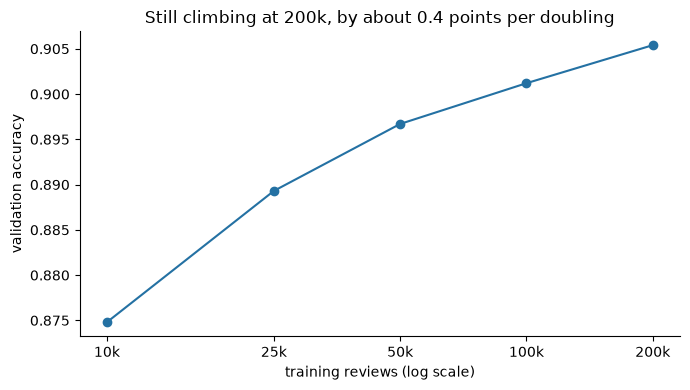

In [8]:
import matplotlib.pyplot as plt

curve = {int(n): a for n, a in tuned["learning_curve_accuracy"].items()}
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(list(curve), list(curve.values()), marker="o", color="#2471a3")
ax.set_xscale("log")
ax.set_xticks(list(curve), [f"{n // 1000}k" for n in curve])
ax.minorticks_off()
ax.set_xlabel("training reviews (log scale)")
ax.set_ylabel("validation accuracy")
ax.set_title("Still climbing at 200k, by about 0.4 points per doubling")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("../reports/figures/learning_curve.png", dpi=150)

The curve flattens but hasn't stopped: 87.5% at 10k, 90.1% at 100k, 90.5% at 200k. The 3.4M reviews left in the full train set would add something, likely under a point for this model. Decision 2 in ARCHITECTURE.md is updated with this.

In [9]:
tuned["title_ablation"]

{'title + body': 0.9054,
 'body only': 0.88,
 'with title minus body only, 95%': [0.0222, 0.0283]}

The title is worth 2.2 to 2.8 points (paired interval), as the EDA suggested: titles like "Waste of money" are the verdict in three words.

,bin,rows,mean_predicted,observed_positive
0,0.0-0.1,6289,0.0271,0.0213
1,0.1-0.2,1423,0.1443,0.0991
2,0.2-0.3,915,0.2464,0.2087
3,0.3-0.4,712,0.3484,0.2921
4,0.4-0.5,648,0.4518,0.4090
5,0.5-0.6,647,0.5514,0.5425
6,0.6-0.7,685,0.6522,0.6730
7,0.7-0.8,921,0.7536,0.7948
8,0.8-0.9,1460,0.8547,0.9123
9,0.9-1.0,6300,0.9714,0.9817


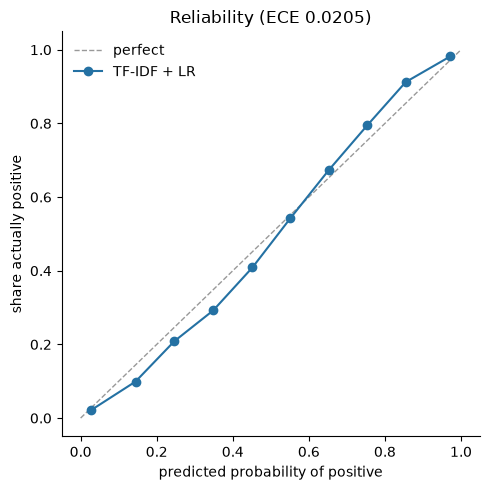

In [10]:
cal = pd.DataFrame(tuned["calibration"]["bins"])
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], color="#999999", lw=1, ls="--", label="perfect")
ax.plot(
    cal["mean_predicted"],
    cal["observed_positive"],
    marker="o",
    color="#2471a3",
    label="TF-IDF + LR",
)
ax.set_xlabel("predicted probability of positive")
ax.set_ylabel("share actually positive")
ax.set_title(f"Reliability (ECE {tuned['calibration']['ece']})")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("../reports/figures/reliability.png", dpi=150)
cal[["bin", "rows", "mean_predicted", "observed_positive"]]

Well calibrated overall (ECE 0.02, Brier 0.07). The gaps that are there all point the same way: the scores are pulled slightly towards 0.5. Of reviews scored 0.3-0.4, 29% are positive; of those scored 0.8-0.9, 91% are. So the model is a little *under*confident: a review it scores 0.35 is a complaint a bit more often than the score says. That's the usual effect of the L2 penalty in logistic regression, and harmless for ranking.